We're going to be building Food Vision Big, using all of the data from the Food101 dataset.

Yep. All 75, 750 training images and 25, 250 testing images.

And guess what...

This time **we've got the goal of beating [DeepFood](https://www.researchgate.net/publication/304163308_DeepFood_Deep_Learning-Based_Food_Image_Recognition_for_Computer-Aided_Dietary_Assessment)**, a 2016 paper which used a Convolutional Neural Network trained for 2-3 days to achieve 77.4% top-1 accuracy.

> 🔑 **Note: Top-1 accuracy** means "accuracy for the top softmax activation value output by the model" (because softmax outputs a value for every class, but top-1 means only the highest one is evaluated). **Top-5 accuracy** means "accuracy for the top 5 softmax activation values output by the model". In other words, did the true label appear in top-5 activation values? Top-5 accuracy scores are usually noticeably higher than top-1.

|   | 🍔👁️**Food Vision Big** | 🍔👁️**Food Vision mini** |
| --- | --- | --- |
| Dataset source | TensorFlow Datasets | Preprocessed download from Kaggle |
| Train data | 75, 750 images | 7, 575 images |
| Test data | 25, 250 images | 25, 250 images |
| Mixed precision | Yes | No |
| Data loading | Performance tf.data API | TensorFlow pre-built function |
| Target results | 77.4% top-1 accuracy (beat [DeepFood paper](https://arxiv.org/abs/1606.05675)) | 50.76% top-1 accuracy (beat [Food101 paper](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/static/bossard_eccv14_food-101.pdf)) |

*Table comparing difference between Food Vision Big (this notebook) versus Food Vision mini (previous notebook).*

Alongside attempting to beat the DeepFood paper, we're going to learn about two methods to significantly improve the speed of our model training:
1. Prefetching
2. Mixed precision training

But more on these later

# What we're going to cover

* Using TensorFlow DAtasets to download and explore data

* Creating preprocessing function for our data

* Batching & prepraring datasets for modelling (**making our datasets run fast**)

* Creating modelling callbacks

* Building a feature extraction model

* Fine-tuning the feature extraction model

* Viewing training results on TensorBoard

## Check GPU

For this notebook, we're going to be doing something different.

We're going to be using mixed precision training.

Mixed precision training was introduced in [TensorFlow 2.4.0](https://blog.tensorflow.org/2020/12/whats-new-in-tensorflow-24.html)

What does **mixed precision training** do?

Mixed precision training uses a combination of single precision (flota32) and half-precision (float-16) data types to speed up model training (upto 3x on modern GPUs).

We'll talk more on this later but in the meantime you can read the [TensorFlow documentation on mixed precision](https://www.tensorflow.org/guide/mixed_precision) for more details.

For now, before we can move forward if we want to used mixed precision training, we need to make sure the GPU powering our Google Colab instance (if you're using Google Colab) is compatible.

For mixed precision training to work, **we need access to a GPU with a compute compatability score of 7.0+.**

Google Colab offeres several kinds of GPUs.

However, some of them **aren;t compatible with mixed precision training.**

Therefore to make sure you have access to mixed precision training in Google Colab, you can check your GPU compute capability score on [Nvidia's developer website.](https://developer.nvidia.com/cuda-gpus#compute)

As of June 2026, the GPUs available on Google Colab which allow mixed precision training are:
* NVIDIA A100 (available with Google Colab Pro)
* NVIDIA Tesla T4

In [ ]:
# Getting GPU name
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-35a36e9a-af63-4dd4-a098-58996746b968)


In [ ]:
import tensorflow as tf
print(f"TensorFlow version: {tf.__version__}")

# adding timestamp
import datetime
print(f"Notebook last run (end-to-end): {datetime.datetime.now()}")

TensorFlow version: 2.21.0
Notebook last run (end-to-end): 2026-08-23 12:07:50.869798


## Getting Helper Functions

We've created a series of helper functions throughout the previous notebooks in the course. Instead of rewriting them (tedious), we'll import the [helper_functions.py](https://github.com/mrdbourke/tensorflow-deep-learning/blob/main/extras/helper_functions.py) file from the GitHub repo.

In [ ]:
import os

if not os.path.exists('helper_functions.py'):
  !wget https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/extras/helper_functions.py
else:
  print("[INFO] 'helper_functions.py' already exists, skipping download.")

--2026-09-20 10:35:34--  https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/extras/helper_functions.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10246 (10K) [text/plain]
Saving to: ‘helper_functions.py’

helper_functions.py 100%[===================>]  10.01K  --.-KB/s    in 0s      

2026-09-20 10:35:34 (23.2 MB/s) - ‘helper_functions.py’ saved [10246/10246]



In [ ]:
from helper_functions import create_tensorboard_callback, plot_loss_curves, compare_historys

## Using TensorFlow Datasets to Download Data

In previous notebooks, we've downloaded our food images (from [Food101 dataset](https://www.kaggle.com/dansbecker/food-101/home)) from Google Storage.

And this is a typical workflow you'd use if you're working on your own datasets.

However, there's another way to get datasets ready to use with TensorFlow.

For many of the most popular datasets in the machine learning world (often referred to and used as benchmarks), you can access them through [TensorFlow Datasets (TFDS)](https://www.tensorflow.org/datasets/overview).

What is **TensorFlow Datasets**?

A place for prepared and ready-to-use machine learning datasets.

Why use TensorFlow Datasets?
* Load data already in Tensors
* Practice on well established datasets
* Experiment with different data loading techiniques (like we're going to use in this notebook)
* Experiment with new TensorFlow features quickly (such as mixed precision training)

Why not use TensorFlow Datasets?
* The datasets are static (they don't change, like you real-world datasets would)

* Might not be suited for your particular problem (but great for experimenting)

To begin using TensorFlow Datasets we can import it under the alias `tfds`.

In [ ]:
import tensorflow_datasets as tfds

To find all the available datasets in TensorFlow Datasets, you can use the `list_builders()` method.

After doing so, we can check to see if the one we're after (`"food101"`) is present.

In [ ]:
import tensorflow_datasets as tfds

# setting our target dataset
target_dataset = 'food101'

try:
    # Try to get all available datasets using list_builders()
    datasets_list = tfds.list_builders()
    print(f"'{target_dataset}' in TensorFlow Datasets: {target_dataset in datasets_list}")
except AttributeError:
    print(f"Warning: 'tfds.list_builders()' is not available. Attempting to check for '{target_dataset}' directly.")
    # Fallback: check if the builder for 'food101' can be created
    try:
        builder = tfds.builder(target_dataset)
        print(f"'{target_dataset}' builder can be initialized (implies it exists): True")
    except Exception as e:
        print(f"'{target_dataset}' builder cannot be initialized: False. Error: {e}")

ERROR:absl:Detected incompatible Protobuf Gencode/Runtime versions when loading tensorflow_metadata/proto/v0/anomalies.proto: gencode 6.31.1 runtime 5.29.6. Runtime version cannot be older than the linked gencode version. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/__init__.py", line 79, in <module>
    from tensorflow_datasets import rlds  # pylint: disable=g-bad-import-order
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/rlds/__init__.py", line 21, in <module>
    from tensorflow_datasets.rlds import envlogger_reader
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/rlds/envlogger_reader.py", line 21, in <module>
    from tensorflow_datasets.core.utils.lazy_imports_utils import tree
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/co

'food101' builder cannot be initialized: False. Error: module 'tensorflow_datasets' has no attribute 'builder'


### Fixing TensorFlow Datasets Compatibility Issues

The previous cell's error messages, including `ERROR:absl:Detected incompatible Protobuf Gencode/Runtime versions` and `module 'tensorflow_datasets' has no attribute 'builder'`, indicate a version mismatch between `tensorflow-datasets` and its underlying dependencies (like Protobuf).

To resolve this, we'll reinstall `tensorflow-datasets` and `tensorflow` to ensure compatible versions are installed. After running the next cell, **please restart your Colab runtime** (Runtime -> Restart runtime) and then run all cells from the beginning.

In [ ]:
# Uninstall and reinstall tensorflow-datasets and tensorflow to fix compatibility issues
!pip uninstall -y tensorflow-datasets tensorflow
!pip install --upgrade tensorflow-datasets tensorflow

Found existing installation: tensorflow-datasets 4.9.10
Uninstalling tensorflow-datasets-4.9.10:
  Successfully uninstalled tensorflow-datasets-4.9.10
Found existing installation: tensorflow 2.20.0
Uninstalling tensorflow-2.20.0:
  Successfully uninstalled tensorflow-2.20.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 57.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 797.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 123.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 34.9 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
  Attempting uninstall: h5py
    Found existing installation: h5py 3.16.0
    Uninstalling h5py-3.16.0:
      Successfully uninstalled h5py-3.16.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are in

In [ ]:
!pip install importlib_resources

Beautiful! It looks like the dataset we're after is available (note: there are plenty more available but we're on Food101).

To get access to the Food101 dataset from TFDS, we can use the [tfds.load()](https://www.tensorflow.org/datasets/api_docs/python/tfds/load) method.

In particular, we'll have to pass it a few parameters to let it know what we're after:
* `name` (str) : the target dataset (e.g. `"food101"`)

* `split` (list, optional) : what splits of the dataset we're after (e.g. `["train", "validation"])
  * the `split` parameter is quite tricky. See [the documentation for more](https://github.com/tensorflow/datasets/blob/master/docs/splits.md).

* `shuffle_files` (bool) : whether or not to shuffle the files on download, defaults to `False`

* `as_supervised` (bool) : `True` to download data samples in tuple format (`(data, label)`) or `False` for dictionary format

* `with_info` (bool) : `True` to download dataset metadata (labels, number of samples, etc.)

> 🔑 **Note:** Calling the `tfds_load()` method will start to download a target dataset to disk if the `download=True` parameter is set (default). This dataset could be 100GB+, so make sure you have enough space.

In [ ]:
# Load in the data
(train_data, test_data), ds_info = tfds.load(name='food101', # target dataset to get from TFDS
                                             split=['train', 'validation'], # what splits of data should we get? note: not all datasets have train, valid, test
                                             shuffle_files=True, # shuffle files on download?
                                             as_supervised=True, # download data in tuple format (sample, label), e.g. (image, label)
                                             with_info=True) # include dataset metadata? is so, tfds.load returns tuple (data, ds_info)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.CGCHZB_2.0.0/food101-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.CGCHZB_2.0.0/food101-validation.tfrecord-[0-9][0-9][0-9…

Dataset food101 downloaded and prepared to /root/tensorflow_datasets/food101/2.0.0. Subsequent calls will reuse this data.


### Fixing `importlib_resources` ModuleNotFoundError

The `ModuleNotFoundError: No module named 'importlib_resources'` indicates that a necessary dependency for `tensorflow-datasets` is missing. To resolve this, we will explicitly install `importlib_resources`.

After running the next cell, **please restart your Colab runtime** (Runtime -> Restart runtime) and then run all cells from the beginning.

In [ ]:
# Install importlib_resources to resolve ModuleNotFoundError
!pip install importlib_resources

# Note: After running this cell, please restart your Colab runtime (Runtime -> Restart runtime) and then run all cells from the beginning.

Wonderful! After a few minutes of downloading, we've now got access to entire Food101 dataset (in tensor format) ready for modelling.

Now let's get a little information for our dataset, starting with the class names.

Getting class names from a TensorFlow Datasets dataset requires downloading the "`dataset_infor`" variable (by using the `as_superrvised=True` parameter in the `tdds.load() method, **note:** this will only work on supervised datasets in TFDS).

We can access the class names of a particular dataset using the `dataset_info.features` attribute and accessing `names` attribute of the `"label"` key.

In [ ]:
# features of Food101 TFDS
ds_info.features

FeaturesDict({
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=101),
})

In [ ]:
# getting class names
class_names = ds_info.features['label'].names
class_names[:10]

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito']

In [ ]:
with open('class_names.txt', 'w') as f:
  f.write('\n'.join(class_names))

## Exploring the Food101 data from TensorFlow Datasets

Now we've downloaded the Food101 dataset from TensorFlow Datasets, how about we do what any good data explorer should?

In other words, "visualize, visualize, visualize".

Let's find out a few details about our dataset:
* The shape of our inpute data (image tensors)

* The datatype of our input data

* What the labels of our input data look like (e.g. one-hot encoded versus label-encoded)

* Do the labels match up with the class names?

To do, let's take on sample off the training data (using the [`.take()` method](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#take)) and explore

In [ ]:
# taking one sample off the training data
train_one_sample = train_data.take(1) # samples are in format (image_tensor, label)

Because we used he `as_supervised=True` parameter in our `tfds.load()` method above, data samples come in the tuple format structure `(data, label)` or in our case `(image_tensor, label)`.

In [ ]:
# what does one sample of our training data look like?
train_one_sample

<_TakeDataset element_spec=(TensorSpec(shape=(None, None, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>

Let's loop through our single training sample and get some info from the `image_tensor` and `label`.

In [ ]:
# output info about our training sample
for image, label in train_one_sample:
  print(f"""
  Image shape: {image.shape}
  Image dtype: {image.dtype}
  Target class from Food101 (tensor form): {label}
  Class name (str form): {class_names[label.numpy()]}
        """)


  Image shape: (512, 512, 3)
  Image dtype: <dtype: 'uint8'>
  Target class from Food101 (tensor form): 56
  Class name (str form): huevos_rancheros
        


Because we set the `shuffle_files=True` parameter in our `tfds.load()` method above, running the cell above a few times will give a different result each time.

Checking these you might notice some of the images have different shapes, for example `(512, 342, 3)` and `(512, 512, 3)` (height, widht, colour_channels).

Let's see what one of the image tensors from TFDS's Food101 dataset look like.

In [ ]:
# what does an image tensor from TFDS's Food101 look like?
image

<tf.Tensor: shape=(512, 512, 3), dtype=uint8, numpy=
array([[[233, 253, 251],
        [231, 253, 250],
        [228, 254, 251],
        ...,
        [ 85,  82,  89],
        [ 68,  67,  75],
        [ 57,  57,  67]],

       [[232, 254, 252],
        [229, 254, 251],
        [226, 255, 251],
        ...,
        [121, 116, 120],
        [100,  99, 104],
        [ 86,  85,  91]],

       [[228, 254, 253],
        [226, 255, 253],
        [223, 255, 252],
        ...,
        [164, 159, 155],
        [145, 141, 138],
        [128, 127, 125]],

       ...,

       [[ 66, 112, 164],
        [ 67, 113, 163],
        [ 55,  99, 148],
        ...,
        [  5,  14,  23],
        [  9,  18,  27],
        [  8,  17,  26]],

       [[ 76, 123, 177],
        [ 75, 122, 176],
        [ 70, 116, 168],
        ...,
        [  5,  14,  23],
        [  9,  18,  25],
        [  7,  16,  23]],

       [[ 80, 129, 185],
        [ 71, 121, 174],
        [ 74, 121, 175],
        ...,
        [  7,  16,  2

In [ ]:
# what are the min and max values?
tf.reduce_min(image), tf.reduce_max(image)

(<tf.Tensor: shape=(), dtype=uint8, numpy=0>,
 <tf.Tensor: shape=(), dtype=uint8, numpy=255>)

Alright looks like our image tensors have values between 0 & 255 (standard red, green, blue colour values) and the values are of data type `unit8`.

We might have to preprocess these before passing them to a neural network. But we'll handle this later.

In the meantime, let's see if we can plot an image sample.

## Plot an image from TensorFlow Datasets

We've seen our image tensors in tensor format, now let's really adher to our motto.

"Visualize, visualize, visualize!"

Let's plot one of the image samples using [`matplotlib.pyplot.imshow()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) and set the title to target class name.

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

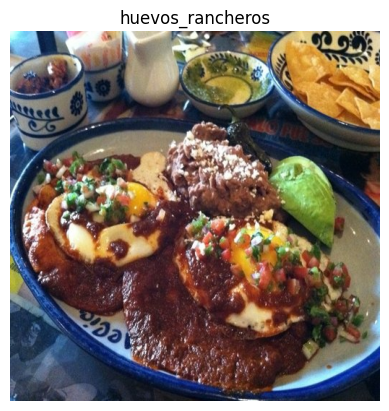

In [ ]:
# plotting an image tensor
import matplotlib.pyplot as plt
plt.imshow(image)
plt.title(class_names[label.numpy()]) # adding title to image by indexing on class_names list
plt.axis(False)

Delicious!

Okay, looks like the Food101 data we've got from the TFDS is similar to the datasets we've been using in previous notebooks.

Now let's preprocess it and get it ready for use with a neural network.

## Creating preprocessing functions for our data

In previous notebooks, when our images were in folder format we used the method [`tf.keras.utils.image_dataset_from_directory()`](https://www.tensorflow.org/api_docs/python/tf/keras/utils/image_dataset_from_directory) to lead them in.

Doing this meant our data was loaded into a format ready to be used with our models.

However, since we've downloaded the data from TensorFlow Datasets, there are a couple of preprocessing steps we have to take before it's ready to model.

More specifically, our data is currently:
* in `unnit8` data type

* Comprised of all different sized tensors (different sized images)

* Not scaled (the pixel values are between 0 & 255)

Whereas, models like data to be:
* in `float32` data type

* Have all of the same size tensors (batches require all tensors have the same shape, e.g. `(224, 224, 3)`)

* Scaled (values between 0 & 1), also called normalized

To take care of these, we'll create a `preprocess_img()` function which:
* Resizes an inpt image tnesor to a specified size using [`tf.image.resize()`](https://www.tensorflow.org/api_docs/python/tf/image/resize)

* Converts an inpt image tensor's current datatype to `tf.float32` using [`tf.cast()`](https://www.tensorflow.org/api_docs/python/tf/cast)

> 🔑 **Note:** Pretrained EfficientNetBX models in [`tf.keras.applications.efficientnet`](https://www.tensorflow.org/api_docs/python/tf/keras/applications/efficientnet) (what we're going to be using) have rescaline built-in. But for many other model architectures you'll want to rescale your data (e.g. get its values between 0 & 1). This could be incorporated inside your "`preprocess_img()`" function (like the one below) or within your model as a [`tf.keras.layers.Rescaling`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Rescaling) layer.

In [ ]:
# Make a function for preprocessing images
def preprocess_img(image, label, img_shape=224):
    """
    Converts image datatype from 'uint8' -> 'float32' and reshapes image to
    [img_shape, img_shape, color_channels]
    """
    image = tf.image.resize(image, [img_shape, img_shape]) # reshape to img_shape
    return tf.cast(image, tf.float32), label # return (float32_image, label) tuple

Our `preprocess_img()` above takes image and label as input (even though it does nothing to the label) because our dataset is currently in the tuple structure `(image, label)`.

Let's try our function out on a target image.

In [ ]:
# preprocessing a single sample image and checking the outputs
preprocessed_img = preprocess_img(image, label)[0]
print(f"Image before preprocessing: \n {image[:2]}..., \nShape: {image.shape}, \nDatatype: {image.dtype}\n")
print(f"Image after preprocessing: \n {preprocessed_img[:2]}..., \nShape: {preprocessed_img.shape}, \nDatatype: {preprocessed_img.dtype}\n")

Image before preprocessing: 
 [[[233 253 251]
  [231 253 250]
  [228 254 251]
  ...
  [ 85  82  89]
  [ 68  67  75]
  [ 57  57  67]]

 [[232 254 252]
  [229 254 251]
  [226 255 251]
  ...
  [121 116 120]
  [100  99 104]
  [ 86  85  91]]]..., 
Shape: (512, 512, 3), 
Datatype: <dtype: 'uint8'>

Image after preprocessing: 
 [[[230.65816 253.64285 251.     ]
  [222.99998 254.97449 252.19388]
  [207.06633 255.      250.36734]
  ...
  [140.66287 129.52519 121.22428]
  [121.14268 115.26515 116.95397]
  [ 83.95363  83.08119  89.63737]]

 [[221.47449 254.37755 253.33163]
  [214.5102  255.      253.92348]
  [198.41327 254.58673 251.96939]
  ...
  [208.66318 195.82143 173.40823]
  [197.03056 190.1071  174.83162]
  [175.54036 171.6169  161.21384]]]..., 
Shape: (224, 224, 3), 
Datatype: <dtype: 'float32'>



Excellent! Looks like our `preprocess_img()` function is working as expected.

The input image gets converted from `unit8` to `float32` and gets reshaped from its current shape to `(224, 224, 3)`.

How does it look?

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

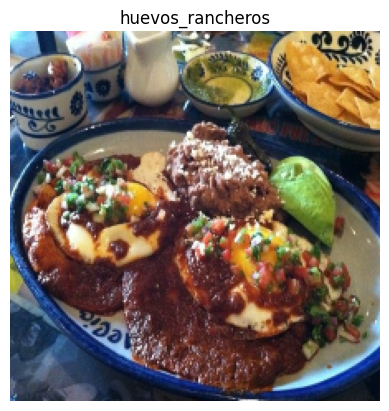

In [ ]:
# we can still plot our preprocessed image as long as we
# divide by 255 (for matplotlib compatiability)
plt.imshow(preprocessed_img/255.)
plt.title(class_names[label])
plt.axis(False)

## Batch & prepare datasets

Before we can model our data, we have to turn it into batches.

Why?

Becuase computing on batches is memory efficient.

We turn our data from 101,000 image tensors and labels (train and test combined) into batches of 32 images and label pairs, thus enabling it to fit into the memory of our GPU.

To do this in effective way, we're going to be leveraging a numbe of methods from the [`tf.data` API](https://www.tensorflow.org/api_docs/python/tf/data).

> 📖 **Resource:** For loading data in the most performant way possible, see the TensorFlow documentation on [**Better performance with the tf.data API**](https://www.tensorflow.org/guide/data_performance).

Specifically, we're going to be using:
* [`map()`](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#map) - maps a predefined function to a target dataset (e.g. `preprocess_img()` to our image tensors)

* [`shuffle()`](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#shuffle) - randomly shuffles the elements of a target dataset up `buffer_size` (ideally, the `buffer_size` is equal to the size of the dataset, however, this may have implications on memory)

* [`batch()`](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#batch) - turns elements of a target dataset into batches (size defined by parameter `batch_size`)

* [`prefetch()`](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#prefetch) - prepares subsequent batches of data whilst other batches of data are being computed on (improves data loading speed but costs memory)

* Extra [`cache()`](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#cache) - caches (saves them for later) elements in a target dataset, saving loading time (will only work if your dataset is small enough to fit in memory, standard Colab instances only have 12GB of memory)

Things to note:
*  Can't batch tensors of different shape (e.g. different image sizes, need to reshape images first, hence out `preprocess_img()` function)

* `shuffle()` keeps a buffer of the number you pass it images shuffled, ideally this number would be all of the samples in your training set, however, if your training set is large, this buffer might not fit in memory (a failry large number like 1000 or 10000 is usually suffice for shuffling)

* For methods with the `num_parallel_calls` parameter available (such as `map()`), setting it to `num_parallel_call=tf.data.AUTOTUNE` will parallize preprocessing and significantly improve speed

* Can't use `cache()` unless your dataset can fit in memory

Woah, the above is a lot. But once we've coded below, it'll start to make sense.

We're going through the things in the following order:
```
Original dataset (e.g. train_data) -> map() -> shuffle() -> batch() -> prefetch() -> PrefetchDataset
```
This is like saying,
> "Hey, map this preprocessing fnction across our training dataset, then shuffle a number of elements before batching them toget and makesure you prepare new batches (prefetch) whilst the model is looking through the current batch".

![](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/07-prefetching-from-hands-on-ml.png)
*What happens when you use prefetching (faster) versus what happens when you don;t use prefetching (slower). **Source:** Page 422 of [Hands On Machine Learning with Scikit-Learn, Keras & TensorFlow Book by Aurelien Geron.](https://www.oreilly.com/library/view/hands-on-machine-learning/9781492032632/)*

In [ ]:
# mapping preprocessing function to training data (and paralellize)
train_data = train_data.map(map_func=preprocess_img)

# Shuffle train_data and turn it into batches and prefetch it (load it faster)
train_data = train_data.shuffle(buffer_size=1000).batch(batch_size=32).prefetch(buffer_size=tf.data.AUTOTUNE)

# Map preprocessing function onto test data
test_data = test_data.map(preprocess_img)

# Turn test data into batches (don't need to shuffle)
test_data = test_data.batch(32).prefetch(tf.data.AUTOTUNE)

And now let's check out what our prepared datasets look.

In [ ]:
train_data, test_data

(<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>,
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>)

Excellent! Looks like our data is now in tuples of `(image, label)` with datatypes of `(tf.float32, tf.int64)`, just what our model is after.

> 🔑**Note:** You can get away without calling the `prefetch()` method on the end of your datasets, however, you'd probably see significantly slower data loading speeds when building a model. So most of your dataset input pipelines should end with a call to [`prefetch()`](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#prefetch).

Onward.

## Create modelling callbacks

Since we're going to be training on a large amount of data and training could take a long time, it's a good idea to set up some modelling callbacks so we be sure of things like our model's training logs being tracked and our model being checkpointed (saved) after various training milestones.

To do each of these we'll use the following callbacks:
* [`tf.keras.callbacks.TensorBoard()`](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/TensorBoard) - allows us to keep track of our model's training history so we can inspect it later (**note:** we've created this callback before have imported it from `helper_functions.py` as `create_tensorboard_callback()`)

* [`tf.keras.callbacks.ModelCheckpoint()`](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/ModelCheckpoint) - saves our model's progress at various intervals so we can load it and reuse it later without having to retrain it.
  * Checkpointing is also helpful so we can start fine-tuning our model at a particular epoch and revert back to a previous state if fine-tuning offeres no benifits.

In [ ]:
# creating TensorBoard callback (already have "create_tensorbard_callback()" from a previous notebook)
from helper_functions import create_tensorboard_callback

# creating ModelCheckpoint callback to save model's progress
checkpoint_path = 'model_checkpoint/cp.weights.h5' # saving weights requires ".ckpt" extension
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(checkpoint_path,
                                                      monitor='val_accuracy', # save the model weights with the best validation accuracy
                                                      save_best_only=True, # only saves the best weights
                                                      save_weights_only=True, # only saves model weights (not the entire model)
                                                      verbose=0) # don't print our whether or not model is being saved

## Setup mixed precision training

We touched on mixed precision training above

However, we didn't quite explain it.

Normally, tensors in TensorFlow default to the float32 datatype (unless otherwise specified)

In computer science, float32 is also know as [single-precision floating point format](https://en.wikipedia.org/wiki/Single-precision_floating-point_format). The 32 means it usually occupies 32 bits in computer memory.

Your GPU has a limited memory, therefore it can only handle a numbe of float32 tensors at the same time.

This is where mixed precision training comes in.

Mixed precision training involves using a mix of float16 and float32 tensors to make better use of your GPU's memory.

Can you guess what float16 means?

Well, if you thought since float32 meant single-precision floating point, you might've guessed float16 means [half-precision floating point format](https://en.wikipedia.org/wiki/Half-precision_floating-point_format). And if you did, you're right! And if not, no trouble, now you know.

For tensors in float16 format, each element occupoes 16 bits in computer memory.

So, where does this leave us?

As mentioend before, when using mixed precision training, your model will make use of float32 and float16 data types to use less memory where possible and in turn run faster (using less memory per tensor means more tensors can be computed on simultaneously).

As a result using mixed precision training can improve your performance on modern GPU's (those with a compute capability score of 7.0+) by up to 3x.

For a more detailed explanation, I encourage you to read through [TensorFlow mixed precision guide](https://www.tensorflow.org/guide/mixed_precision) (i'd highly recommend atleast checking out the summary).

![](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/07-mixed-precision-speedup-equals-3x-gpu.png)
*Because mixed precision uses a combination of float32 and float16 data types, you may see up tp 3x speedup on modern GPUs.*

>🔑**Note:** If your GPU doesn't have a score of over 7.0+ (e.g. P100 in Google Colab), mixed precision won't work (see [**"Supported Hardware"**](https://www.tensorflow.org/guide/mixed_precision#supported_hardware) ub the mixed precision guide for more).

> 📖**Resource:** If you'd like to learn more about precision in computer science (the detail to which a numerical quantity is represented by a computer), see the [**Wikipedia page**](https://en.wikipedia.org/wiki/Precision_(computer_science) (and accompanying resources).

Okay enough talk, let's see how we can turn on mixed precision training in TensorFlow.

The beautiful thing is, the [`tensorflow.keras.mixed_precision`](https://www.tensorflow.org/api_docs/python/tf/keras/mixed_precision/) API has made it very easy for us to get started.

First we'll import the API and then use the [`set_global_policy()`](https://www.tensorflow.org/api_docs/python/tf/keras/mixed_precision/set_global_policy) method to set the *dtype policy* to `"mixed_float16"`.

In [ ]:
# turning on mixed precision training
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy(policy='mixed_float16') # set global policy to mixed precision

Nice! As long as the GPU you're using has a compatability score of 7.0+ the cell above should run without error.

Now we can check the global dtype poicy(the policy which will be used by layers in our model) using the [`mixed_precision.global_policy()`](https://www.tensorflow.org/api_docs/python/tf/keras/mixed_precision/global_policy) method.

In [ ]:
mixed_precision.global_policy() # should output "mixed_float16" (if your GPU is compatible with mixed precision)

<DTypePolicy "mixed_float16">

Great, since the global dtype policy is now `"mixed_float16"` our model will automatically take advantage of float16 variables where possible and in turn speed up training.

## Build feature extraction model

Callbacks: ready to roll.

Mixed precission: turned on.

Let's build a model.

Because our dataset is quite large, we're going to move towards fine-tuning an existing pretrained model (efficientNetB0).

But before we get into fine-tuning, let's set up a feature extraction model.

Recall, the typical oreder for transfer learning is:
1. Build a feature extraction model (replace the top few layers of a pretrained model)

2. Train for a few epochs with lower layers frozen

3. Fine-tune if necessary with multiple layers unfrozen.

![](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/07-feature-extraction-then-fine-tune.png)
*Before fine-tuning, it's best to train a feature extraction model with custom top layers.*

To build the feature extraction model we'll:
* Use `EfficientNetB0` from [`tf.keras.applications`](https://www.tensorflow.org/api_docs/python/tf/keras/applications) pre-trained on ImageNet as our base model
  * We'll download this without the top layers using `include_top=False` parameter so we can creae our own output layers.

* Freeze the base model layers so we can use the pre-trained patterns the base model has found on ImageNet

* Put together the input, base model, pooling and output layers in a [Functional model](https://keras.io/guides/functional_api/)

* Compile the Functional model using the Adam optimizer and [sparse categorical crossentropy](https://www.tensorflow.org/api_docs/python/tf/keras/losses/SparseCategoricalCrossentropy) as the loss function (since our labels **aren't** one-hot encoded)

* Fit the model for 3 epochs using the TensorBoard and ModelCheckpoint callbacks

> 🔑**Note:** Since we're using mixed precision training, our model needs a separate output layer with a hard-coded `dtype=float32`, for example, `layers.Activation("softmax", dtype=float32)`. This ensures the outputs of our model are returned back to the float32 data type which is more numerically stable than the float16 datatype (important for loss calculatations). See the [**"Building the model"**](https://www.tensorflow.org/guide/mixed_precision#building_the_model) section in the TensorFlow mixed precision guide for more.

![](https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/images/07-mixed-precision-code-before-and-after.png)
*Turning mixed precision on in TensorFlow with 3 lines of code*

In [ ]:
from tensorflow.keras import layers

# creating base model
input_shape = (224, 224, 3)
base_model = tf.keras.applications.EfficientNetB0(include_top=False)
base_model.trainable = False # freezing base model layers

# creating functional model
inputs = layers.Input(shape=input_shape, name='input_layer')

# data augmentation layers
x = layers.RandomFlip('horizontal', name='data_aug_flip')(inputs)
x = layers.RandomRotation(0.15, name='data_aug_rotation')(x)
x = layers.RandomTranslation(height_factor=0.1, width_factor=0.1, name='data_aug_translation')(x)
x = layers.RandomContrast(factor=0.2, name='data_aug_contrast')(x)

# note: EfficientNetBX models have rescaling built-in but if your model didn't you could have a layer like below
# x = layers.Rescaling(1./255)(x)

x = base_model(inputs, training=False) # setting base model to inference mode only

x = layers.GlobalAveragePooling2D(name='pooling_layer')(x)
x = layers.Dropout(0.3, name='head_dropout')(x)
x = layers.Dense(len(class_names))(x) # want one output return per class

# separate activation of output layer so we can output float32 activations
outputs = layers.Activation('softmax', dtype=tf.float32, name='softmax_float32')(x)

model = tf.keras.Model(inputs, outputs)

# compiling the model
model.compile(loss='sparse_categorical_crossentropy', # use spares_categoical_crossentropy when labels are *not* one-hot encoded
              optimizer='adam',
              metrics=['accuracy'])

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# checking out our model
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_layer                   │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 101)            │       129,381 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_float32 (Activation)    │ (None, 101)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,178,952 (15.94 MB)

 Trainable params: 129,381 (505.39 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## Checking layer dtype policies (are we using mized precision?)

Model ready to go!

Before we said the mixed precision API will automatically change our layers dtype policy to whatever the gloabl dtype policy is (in our case it's `"mixed_float16"`).

We can check this by iterating through our model's layers and printing layer attribute such as `dtype` and `dtype_policy`.

In [ ]:
# checking the dtype_policy attributes of layers in our model
for layer in model.layers:
  print(layer.name, layer.trainable, layer.dtype, layer.dtype_policy) # check the dtype policy of layers

input_layer True float32 <DTypePolicy "mixed_float16">
efficientnetb0 False float32 <DTypePolicy "mixed_float16">
pooling_layer True float32 <DTypePolicy "mixed_float16">
head_dropout True float32 <DTypePolicy "mixed_float16">
dense True float32 <DTypePolicy "mixed_float16">
softmax_float32 True float32 <DTypePolicy "float32">


Goig through the above we see:
* `layer.name` (str): a layer's human readable name, can be defined by the `name` parameter on construction

* `layer.trainable` (bool): whether or not a layer is trainable (all of our layers are trainable except the efficientnetb0 layer since we set it's `trainable` attribute to `False`)

* `layer.dtype`: the data type a layer stores its variables in.

* `layer.dtype_policy`: the data type a layer computes in

> 🔑 **Note:** A layer can have a dtype of `float32` and a dtype policy of `"mixed_float16"` because it stores its variables (weights & biases) in `float32` (more numerically stable), however it computes in `float16` (faster)

We can also check the same details for our model's base model

In [ ]:
# checking the layers in the base model and seeing whta dtype policy they're using
for layer in model.layers[1].layers[:20]: # only the first 20 layers to save output space
  print(layer.name, layer.trainable, layer.dtype, layer.dtype_policy)

input_layer_3 False float32 <DTypePolicy "mixed_float16">
rescaling_4 False float32 <DTypePolicy "mixed_float16">
normalization_2 False float32 <DTypePolicy "mixed_float16">
rescaling_5 False float32 <DTypePolicy "mixed_float16">
stem_conv_pad False float32 <DTypePolicy "mixed_float16">
stem_conv False float32 <DTypePolicy "mixed_float16">
stem_bn False float32 <DTypePolicy "mixed_float16">
stem_activation False float32 <DTypePolicy "mixed_float16">
block1a_dwconv False float32 <DTypePolicy "mixed_float16">
block1a_bn False float32 <DTypePolicy "mixed_float16">
block1a_activation False float32 <DTypePolicy "mixed_float16">
block1a_se_squeeze False float32 <DTypePolicy "mixed_float16">
block1a_se_reshape False float32 <DTypePolicy "mixed_float16">
block1a_se_reduce False float32 <DTypePolicy "mixed_float16">
block1a_se_expand False float32 <DTypePolicy "mixed_float16">
block1a_se_excite False float32 <DTypePolicy "mixed_float16">
block1a_project_conv False float32 <DTypePolicy "mixed_fl

> 🔑 **Note:** The mixed precision API automatically causes layers which can benifit from using the `",oxed_float16"` dtype policy to use it. It also prevents layers which shouldn't use it from using it (e.g. the normalization layer at the start of the base model).

# Fit the feature extraction model

Now that's one good looking model. Let;s fit it to our data shall we?

Three epochs should be enough for our top layers to adjust their weights enough to our food image data.

To save time per epochs, we'll also only validate on 15% of the test data.

In [ ]:
# turning off all warning except for errors
tf.get_logger().setLevel('ERROR')

# fitting the model with callbacks
history_101_food_classes_feature_Extract = model.fit(train_data,
                                                     epochs=5, # since data augmentation is added, training for longer (5 instead of 3 epochs)
                                                     steps_per_epoch=len(train_data),
                                                     validation_data=test_data,
                                                     validation_steps=int(0.15 * len(test_data)),
                                                     callbacks=[create_tensorboard_callback('training_logs',
                                                                                            'efficeintnetb0_101_classes_all_data_feature_extract'),
                                                                model_checkpoint])

Saving TensorBoard log files to: training_logs/efficeintnetb0_101_classes_all_data_feature_extract/20260625-063252
Epoch 1/5
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 355s 109ms/step - accuracy: 0.5375 - loss: 1.9043 - val_accuracy: 0.6875 - val_loss: 1.1794
Epoch 2/5
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 177s 74ms/step - accuracy: 0.6316 - loss: 1.4284 - val_accuracy: 0.7111 - val_loss: 1.0610
Epoch 3/5
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 171s 71ms/step - accuracy: 0.6518 - loss: 1.3350 - val_accuracy: 0.7222 - val_loss: 1.0256
Epoch 4/5
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 171s 72ms/step - accuracy: 0.6640 - loss: 1.2787 - val_accuracy: 0.7259 - val_loss: 0.9990
Epoch 5/5
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 165s 69ms/step - accuracy: 0.6681 - loss: 1.2472 - val_accuracy: 0.7262 - val_loss: 0.9837


Nice. looks like our feature extraction model is performing pretty well. How about we evaluate it on the whole test dataset?

In [ ]:
# evaluatie model (unsaved version) on whole test dataset
results_feature_extract_model = model.evaluate(test_data)
results_feature_extract_model

790/790 ━━━━━━━━━━━━━━━━━━━━ 93s 117ms/step - accuracy: 0.7278 - loss: 0.9974


[0.9973935484886169, 0.7278019785881042]

And since we save the `ModelCheckpoint` callback, we've got a saved version of our model in the `model_checkpoints` directory.

Let;s load it in and make sure it performs just as well.

## Load and evaluate checkpoint weights

We can load in and evaluate our model's checkpoints by:
1. Recreating a new instance of our model called `create_model` by turning our original model creation code into a function called `create_model()`.

2. Compiling our `created_model` with the same loss, optimizer and metrics as the original model (every time you create a new model, you must compile it).

3. Calling the `load_weights()` method on our `created_model` and passing it the path to where our checkpointed weights are stored.

4. Calling `evaluate()` on `created_model` with loaded weights and saving the results.

5. Comparing the `created_model` results to our previous `model` reuslts (these should be the exact same, if not very close).

A reminder, checkpoints are helpful for when you perform an experimentsuch as fine-tuning your model. In the case, youfine-tune your feature extraction model and find it doesm't offere any improvements, you can always revert back to the checkpointed version of your model.

In [ ]:
# function to recreate the original model
def create_model():
  # creating base model
  input_shape = (224, 224, 3)
  base_model = tf.keras.applications.EfficientNetB0(include_top=False)
  base_model.trainable = False # freezing base model layers

  # creating functional model
  inputs = layers.Input(shape=input_shape, name='input_layer')

  # data augmentation layers
  x = layers.RandomFlip('horizontal', name='data_aug_flip')(inputs)
  x = layers.RandomRotation(0.15, name='data_aug_rotation')(x)
  x = layers.RandomTranslation(height_factor=0.1, width_factor=0.1, name='data_aug_translation')(x)
  x = layers.RandomContrast(factor=0.2, name='data_aug_contrast')(x)

  # note: EfficientNetBX models have rescaling built-in but if your model didn't you could have a layer like below
  # x = layers.Rescaling(1./255)(x)

  x = base_model(inputs, training=False) # setting base model to inference mode only

  x = layers.GlobalAveragePooling2D(name='pooling_layer')(x)
  x = layers.Dropout(0.3, name='head_dropout')(x)
  x = layers.Dense(len(class_names))(x) # want one output return per class

  # separate activation of output layer so we can output float32 activations
  outputs = layers.Activation('softmax', dtype=tf.float32, name='softmax_float32')(x)

  model = tf.keras.Model(inputs, outputs)

  return model

# creating and compiling a new version of the original model (new weights)
created_model = create_model()
created_model.compile(loss='sparse_categorical_crossentropy',
                      optimizer=tf.keras.optimizers.Adam(),
                      metrics=['accuracy'])

# loading the saved weights
created_model.load_weights(checkpoint_path)

# evaluating the model with loaded weights
results_created_model_with_loaded_weights = created_model.evaluate(test_data)

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 4 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


790/790 ━━━━━━━━━━━━━━━━━━━━ 89s 77ms/step - accuracy: 0.7278 - loss: 0.9974


Our `created_model` with loaded weights results should be very close to the feature extraction model's results (if the cell below errors, something went wrong).

In [ ]:
# loaded checkpoint weights should return very similar results to the checkpoint weights prior to saving
import numpy as np
assert np.isclose(results_feature_extract_model, results_created_model_with_loaded_weights).all(), "Loaded weights results are not close to original model." # check if all elements in array are close

Cloning the model preserves `dtype_policy`'s if layers (but doesn't preserve weights) so if we wanted to continue fine-tuning our `created_model`, we could and it would still use the mixed precision dtype policy

In [ ]:
# checking the layers in the base model and seeing what dtype policy they're using
for layer in created_model.layers[1].layers[:20]: # checking on the first 20 layers to save printing space
  print(layer.name, layer.trainable, layer.dtype, layer.dtype_policy)

input_layer_4 False float32 <DTypePolicy "mixed_float16">
rescaling_6 False float32 <DTypePolicy "mixed_float16">
normalization_3 False float32 <DTypePolicy "mixed_float16">
rescaling_7 False float32 <DTypePolicy "mixed_float16">
stem_conv_pad False float32 <DTypePolicy "mixed_float16">
stem_conv False float32 <DTypePolicy "mixed_float16">
stem_bn False float32 <DTypePolicy "mixed_float16">
stem_activation False float32 <DTypePolicy "mixed_float16">
block1a_dwconv False float32 <DTypePolicy "mixed_float16">
block1a_bn False float32 <DTypePolicy "mixed_float16">
block1a_activation False float32 <DTypePolicy "mixed_float16">
block1a_se_squeeze False float32 <DTypePolicy "mixed_float16">
block1a_se_reshape False float32 <DTypePolicy "mixed_float16">
block1a_se_reduce False float32 <DTypePolicy "mixed_float16">
block1a_se_expand False float32 <DTypePolicy "mixed_float16">
block1a_se_excite False float32 <DTypePolicy "mixed_float16">
block1a_project_conv False float32 <DTypePolicy "mixed_fl

## Save the whole model to file

We can also save the whole model using the [`save()`](https://www.tensorflow.org/api_docs/python/tf/keras/Model#save) method.

Since, our model is quite large, you might want to save it to Google Drive (if you're using Google Colab) so you can load it in for use later

> 🔑 **Note:** Saving to Google Drive requires mounting Google Drive

In [ ]:
!ls -l /drive/MyDrive/models

total 19192
drwxr-xr-x 2 root root     4096 Jun 23 11:19 07-efficientnetb0-feature-extract-model-mixed-precision.keras
drwxr-xr-x 2 root root     4096 Jun 23 11:21 07_efficientnetb0_feature_extract_model_mixed_precision.keras
-rw-r--r-- 1 root root 19642658 Jun 23 11:27 07_efficientnetb0_feature_extract_model_mixed_precision_model.keras


In [ ]:
# save_path = '/drive/MyDrive/models/07_efficientnetb0_feature_extract_model_mixed_precision_model.keras'
# os.makedirs(save_path) # make directory if it doesn't exist

# save model
model.save('07_efficientnetb0_feature_extract_model_mixed_precision_model.keras')

And again, we can check whether or not our model saved correctly by loading it in and evaluating it.

In [ ]:
# load model previously saved above
loaded_saved_model = tf.keras.models.load_model('/content/drive/MyDrive/models/07_efficientnetb0_feature_extract_model_mixed_precision_model.keras')

Loading a `.keras` model also retains of all the underlying layers `dtype_policy` (we want them to be `"mixed_float16"`)

In [ ]:
# check the layers in the base model and see what dtype policy they're using
for layer in loaded_saved_model.layers[1].layers[:20]: # check only the first 20 layers to save output space
  print(layer.name, layer.trainable, layer.dtype, layer.dtype_policy)

input_layer True float32 <DTypePolicy "mixed_float16">
rescaling False float32 <DTypePolicy "mixed_float16">
normalization False float32 <DTypePolicy "mixed_float16">
rescaling_1 False float32 <DTypePolicy "mixed_float16">
stem_conv_pad False float32 <DTypePolicy "mixed_float16">
stem_conv False float32 <DTypePolicy "mixed_float16">
stem_bn False float32 <DTypePolicy "mixed_float16">
stem_activation False float32 <DTypePolicy "mixed_float16">
block1a_dwconv False float32 <DTypePolicy "mixed_float16">
block1a_bn False float32 <DTypePolicy "mixed_float16">
block1a_activation False float32 <DTypePolicy "mixed_float16">
block1a_se_squeeze False float32 <DTypePolicy "mixed_float16">
block1a_se_reshape False float32 <DTypePolicy "mixed_float16">
block1a_se_reduce False float32 <DTypePolicy "mixed_float16">
block1a_se_expand False float32 <DTypePolicy "mixed_float16">
block1a_se_excite False float32 <DTypePolicy "mixed_float16">
block1a_project_conv False float32 <DTypePolicy "mixed_float16">

In [ ]:
# check loaded model performance (this should be the same as the results_feature_extract_model)
results_loaded_saved_model = loaded_saved_model.evaluate(test_data)
results_loaded_saved_model

790/790 ━━━━━━━━━━━━━━━━━━━━ 156s 106ms/step - accuracy: 0.7278 - loss: 0.9974


[0.997405469417572, 0.7278415560722351]

In [ ]:
# the loaded model's results should equal (or at least be very close) to the model's results prior to saving
assert np.isclose(results_feature_extract_model, results_loaded_saved_model).all()

That's what we want! Our loaded model performing as it should.

> 🔑 **Note:** We spent a fair bit of time making sure our model saved correctly because training on a lot of data can be time-consuming, so we want to make sure we don't have to continaully train from scratch.

## Preparing our model's layers for fine-tuning

Our feature-extraction model is showing some great promise after three epochs. But since we've got so much data. It's probably worthwhile that we see what results we can get with fine-tuning (fine-tuning usually works best when you've got quite a large amount of data).

Remember our goal of beating the [DeepFound paper](https://arxiv.org/pdf/1606.05675.pdf)?

They were able to achieve 77.4% top-1 accuracy on Food101 over 2-3 days of training.

Do you think fine-tuning will get us there?

Let's find out.

To start, let's load in our saved model.

> 🔑 **Note:** It's worth remembering a traditional worflow for fine-tuning is to freeze a pre-trained base model and then train only the output layers for a few iterations so their weights can be updated inline with your custom data (feature extraction). And then unfreeze a number or all of the layers in the base model and continue training until the model stops improving.

Like all good cooking shows, i've saved a model I prepared earlier (the feature extraction model from above) to Google Storage.

We can download it to make sure we're using the same model going forward.

(SavedModel format is now a legacy format, can only be loaded in inference mode using keras TFSM layer, hence, using my `.keras` saved model)

In [ ]:
# getting a summary of our model
loaded_saved_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_layer                   │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 101)            │       129,381 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_float32 (Activation)    │ (None, 101)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,437,720 (16.93 MB)

 Trainable params: 129,381 (505.39 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

 Optimizer params: 258,768 (1010.82 KB)

And now let's make sure our loaded model is performing as expected.

In [ ]:
results_loaded_saved_model

[0.997405469417572, 0.7278415560722351]

Great, our loaded model is performing as expected.

When we first created our model, we froze all of the layers in the base model by setting `base_model.trainable=False` but since we've loaded in our model from file, let's check whether or not the laters are trainable.

In [ ]:
# are any of the layers in our model frozen?
for layer in loaded_saved_model.layers:
  layer.trainable = True # setting all layers to trainable
  print(layer.name, layer.trainable, layer.dtype, layer.dtype_policy) # make sure loaded model is using mixed precision dtype_policy ("mixed_float16")

input_layer True float32 <DTypePolicy "mixed_float16">
efficientnetb0 True float32 <DTypePolicy "mixed_float16">
pooling_layer True float32 <DTypePolicy "mixed_float16">
head_dropout True float32 <DTypePolicy "mixed_float16">
dense True float32 <DTypePolicy "mixed_float16">
softmax_float32 True float32 <DTypePolicy "float32">


Alright, it seems like each layer in our loaded model is trainable. But what if we got a little deeper and inspected each of the layers in our base model.

> 🤔 **Question:** Which layer in the loaded model is our base model?

Before saving the Functional model to a file, we created it with five layers (layers below are 0-indexed):

0. The input layer

1. The pre-trained base model layer ([`tf.keras.applications.efficientnet.EfficientNetB0`](https://www.tensorflow.org/api_docs/python/tf/keras/applications/efficientnet/EfficientNetB0))

2. The pooling layer

3. The fully-connected (dense) layer

4. The output softmax activation (with float32 dtype)

Therefore to inspect our base model layer, we can access the `layers` attribute pf the layer at index 1 in our model.

In [ ]:
# check the layers in the base model and see what dtype policy the're using
for layer in loaded_saved_model.layers[1].layers[:20]:
  print(layer.name, layer.trainable, layer.dtype, layer.dtype_policy)

input_layer True float32 <DTypePolicy "mixed_float16">
rescaling True float32 <DTypePolicy "mixed_float16">
normalization True float32 <DTypePolicy "mixed_float16">
rescaling_1 True float32 <DTypePolicy "mixed_float16">
stem_conv_pad True float32 <DTypePolicy "mixed_float16">
stem_conv True float32 <DTypePolicy "mixed_float16">
stem_bn True float32 <DTypePolicy "mixed_float16">
stem_activation True float32 <DTypePolicy "mixed_float16">
block1a_dwconv True float32 <DTypePolicy "mixed_float16">
block1a_bn True float32 <DTypePolicy "mixed_float16">
block1a_activation True float32 <DTypePolicy "mixed_float16">
block1a_se_squeeze True float32 <DTypePolicy "mixed_float16">
block1a_se_reshape True float32 <DTypePolicy "mixed_float16">
block1a_se_reduce True float32 <DTypePolicy "mixed_float16">
block1a_se_expand True float32 <DTypePolicy "mixed_float16">
block1a_se_excite True float32 <DTypePolicy "mixed_float16">
block1a_project_conv True float32 <DTypePolicy "mixed_float16">
block1a_project

Wonderful, it looks like each layer in our base model is tranable (unfrozen) and every layer which should be using the dtype policy `"mixed_float16"` is using it.

Since, we got so much data (750 images x 101 training classes = 75750 training images), let's keep all of our base model's layers unfrozen.

> 🔑 **Note:** If you've got a small amount of data (less than 100 images per class), you may want to only unfreeze and fine-tune a small number of layers in the base model at a time. Otherwise, you risk overfitting.

## A couple more callbacks

We're about to start fine-tuning a deep learning model with over 200 layers using over 100,000 (75k+ training, 25k+ testing) images, which means our model's training time is probably going to be much longer than before.

> 🤔 **Question:** *How longe does training take?*

It could be a couple of hours or in the case of [DeepFound paper](https://arxiv.org/pdf/1606.05675.pdf) (the baseline we're trying to beat), their best perfoming model took 2-3 days of training time.

You will really only know how long it'll take once you start training.

> 🤔 **Question:** *When do you stop training?*

Ideally, when your model stops improving. But again, due to the nature of deep learning, it can be hard to know when a model will stop improving.

Luckliy, there's a solution: the [`EarlyStopping` callback](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping).

The `EarlyStopping` callback monitors a specified model performance metric (e.g. `val_loss`) and when it stops improving for a specified number of epochs, automatically stops training.

Using the `EarlyStopping` callback combined with the `ModelCheckpoint` callback saving the best perfoming model automaticaly, we could keep our model training for an unlimited number of epochs until it stops improving.

Let's set both of these up to monitor our model's `val_loss`.

In [ ]:
# setup EarlyStopping callback to stop training if model's val_loss doesn;t improve for 3 epochs
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', # watch the val loss metric
                                                  patience=3) # if val loss decreaser for 3 epochs in a row, stop training

# create ModelCheckpoint callback to save best model during fine-tuning
checkpoint_path = 'fine_tune_checkpoints/07_efficientnetb0_101_classes_all_data_fine_tune_model.keras'
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(checkpoint_path,
                                                      save_best_only=True,
                                                      monitor='val_loss')

Woohoo! Fine-tuning callbacks ready.

If you;re planning on training large models, the `ModelCheckpoint` and `EarlyStopping` are two callbacks you'll want to become very familiar with.

We're almost ready to start fine-tuning our model but there's one more callback we're goinh to implement:
[`ReduceLROnPlateau`](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/ReduceLROnPlateau).

Remember how the learning rate is the most important model hyperparameter you can tune? (if not, treat this as a reminder).

Well, the `ReduceLROnPlateaur` callback helps to tune the learning rate for you.

Like the `ModelCheckpoint` and `EarlyStopping` callbacks, the `ReduceLROnPlateau` callback monitors a specified metric and when the metric stops improving, it reduces the learning rate by a specified factor (e.g. divides the learning rate by a factor of 10).

> 🤔 **Question:** *Why lower the learning rate?*

Imagine having a con at the back of the couch and you're trying to grab it with your fingers.

Now think of the learning rate as the size of the movements your hand makes towards the coin.

The closer you get, the smaller you want your hand movemebts to be, otherwise the coin will be lost.

Our model's ideal performance is the equivalent of grabbing the coing. So as training goes on and our model gets closer and closer to it's ideal performance (also called **convergence**), we want the amount it learns to be less and less.

To do this we'll create an instance of teh `ReduceLROnPlateau` callback to monitor the validation loss just like the `EarlyStopping` callback.

Once the validation loss steps improving for two or more epochs, we'll reduce the learning rate by a factor of 5 (e.g. `0.001` to `0.0002`).

And to make sure the learning rate doesn't get too low (and potentially result in our model learning nothing) we'll set the minimum learning rate to `1e-7`.

In [ ]:
# creating learning rate reduction callback
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',
                                                 factor=0.2, # multiply the learning rate by 0.2 (reduce by 5x)
                                                 patience=2,
                                                 verbose=1, # print out when learning rate goes down
                                                 min_lr=1e-7)

Learning rate reduction ready to go!

Now before we start training, we've got to recompile our model.

We'll use sparse categorical crossentropy as the loss and since we're fine tuning, we'll use a 10x lower learning rate than the Adam optimzer's default (`1e-4` instaead of `1e-3`).

In [ ]:
# compile the model
loaded_saved_model.compile(loss='sparse_categorical_crossentropy',
                           optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
                           metrics=['accuracy'])

Okay, model completed.

Now, let's fit it on all of the data.

We'll set it up to run for upto 100 epochs.

Since we're going to be using the `EarlyStopping` callback, it might stop before reaching 100 epochs.

> 🔑 **Note:** Running the cell below will set the model up to fine-tune all of the pre-trained weights in the base model on all of the Food101 data. Doing so with **unoptimized** data pipelines and **without** mixed precision training will take a fairly long time per epochs depending on what type of GPU you're using (about 15-20 minutes on Colab GPUs). But don't worry, **the code we've written above will ensure it runs much faster** (more like 4-5 mins per epoch).

In [ ]:
# start to fine-tune all layers
history_101_food_classes_all_data_fine_tune = loaded_saved_model.fit(train_data,
                                                                     epochs=100, # fine-tune for a maximum of 100 epochs
                                                                     steps_per_epoch=len(train_data),
                                                                     validation_data=test_data,
                                                                     validation_steps=int(0.15 * len(test_data)), # validation during training on 15% of test data
                                                                     callbacks=[create_tensorboard_callback('training_logs', 'efficientb0_101_classes_all_data_fine_tuning'), # track the model training logs
                                                                                model_checkpoint, # save only the bset model during training
                                                                                early_stopping, # stop model training after X epochs of no improvements
                                                                                reduce_lr]) # reduce the learning rate after X epochs of not improvementss

Saving TensorBoard log files to: training_logs/efficientb0_101_classes_all_data_fine_tuning/20260630-054407
Epoch 1/100
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 724s 189ms/step - accuracy: 0.4537 - loss: 2.2332 - val_accuracy: 0.6637 - val_loss: 1.2496 - learning_rate: 1.0000e-05
Epoch 2/100
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 217s 90ms/step - accuracy: 0.6102 - loss: 1.4919 - val_accuracy: 0.7254 - val_loss: 1.0063 - learning_rate: 1.0000e-05
Epoch 3/100
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 218s 91ms/step - accuracy: 0.6647 - loss: 1.2711 - val_accuracy: 0.7534 - val_loss: 0.8994 - learning_rate: 1.0000e-05
Epoch 4/100
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 217s 91ms/step - accuracy: 0.6922 - loss: 1.1539 - val_accuracy: 0.7675 - val_loss: 0.8443 - learning_rate: 1.0000e-05
Epoch 5/100
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 268s 93ms/step - accuracy: 0.7112 - loss: 1.0753 - val_accuracy: 0.7794 - val_loss: 0.7962 - learning_rate: 1.0000e-05
Epoch 6/100
2368/2368 ━━━━━━━━━━━━━━━━━━━━ 214s 89ms/step - accuracy: 0.7272 - lo

In [ ]:
save_path = '/content/drive/MyDrive/models/07_efficientnetb0_fine_tuned_101_classes_mixed_precision.keras'
# os.makedirs(save_dir) # make directory if it doesn't exist

# save model
loaded_saved_model.save(save_path)
print('fine tuned model saved succesfully to gdrive!')

fine tuned model saved succesfully to gdrive!


In [ ]:
!ls -L /content/drive/MyDrive/models/

07_efficientnetb0_feature_extract_model_mixed_precision_model.keras
07_efficientnetb0_fine_tuned_101_classes_mixed_precision.keras


In [ ]:
# import tensorflow as tf

# save_path = '/drive/MyDrive/07-efficientnetb0-fine-tuned-101-classes-mixed-precision.keras'
loaded_saved_model = tf.keras.models.load_model(save_path)

In [ ]:
loaded_saved_model.evaluate(test_data)

790/790 ━━━━━━━━━━━━━━━━━━━━ 93s 79ms/step - accuracy: 0.8268 - loss: 0.6266


[0.6266494989395142, 0.8267722725868225]

> 🔑 **Note:** If you didn't use mixed precision or use techniques such as `prefetch()` in the *Batch & prepare datasets* section, your model fine tuning probably takes up to 2.5 - 3x longer per epoch.

In [ ]:
loaded_saved_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_layer                   │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 101)            │       129,381 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_float32 (Activation)    │ (None, 101)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,452,816 (47.50 MB)

 Trainable params: 4,136,929 (15.78 MB)

 Non-trainable params: 42,023 (164.16 KB)

 Optimizer params: 8,273,864 (31.56 MB)

Excellent! Our saved model is performing as expected (better results than the DeepFound paper!)

Congratulations! You should be excited! You just trained a computer vision model with competitive performance to a research paper and in far less time (our model took ~20 mins to train versus DeepFood's quoted 2-3 days).

In other words, you brought Food Vision to life!

If you really wanted to step things up, you could try using the [`EfficientNetB4`](https://www.tensorflow.org/api_docs/python/tf/keras/applications/EfficientNetB4) model (a larger version of `EfficientNetB0`). At the time of writing, the EfficientNet family has the [state of the art classification results](https://paperswithcode.com/sota/fine-grained-image-classification-on-food-101) on the Food101 dataset.

> 📖 **Resource:** To see which models are currently performing the best on a given dataset or problem type as well as the latest trending machine learning research, be sure to check out [this](http://paperswithcode.com/) and [this for trending papers](https://sotabench.com/).

## Visualiing training logs in tensorboard

In [ ]:
%reload_ext tensorboard
!python -m tensorboard.main --logdir ./training_logs/


NOTE: Using experimental fast data loading logic. To disable, pass
    "--load_fast=false" and report issues on GitHub. More details:
    https://github.com/tensorflow/tensorboard/issues/4784

Serving TensorBoard on localhost; to expose to the network, use a proxy or pass --bind_all
TensorBoard 2.20.0 at http://localhost:6006/ (Press CTRL+C to quit)


In [ ]:
from google.colab import drive
drive.flush_and_unmount()

# Testing code for FoodSight Streamlit implementation

In [ ]:
import tensorflow as tf
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
loaded_saved_model = tf.keras.models.load_model('/content/drive/MyDrive/models/07_efficientnetb0_fine_tuned_101_classes_mixed_precision.keras')
loaded_saved_model

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 428 variables whereas the saved optimizer has 432 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


<Functional name=functional, built=True>

In [ ]:
loaded_saved_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooling_layer                   │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 101)            │       129,381 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_float32 (Activation)    │ (None, 101)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,452,812 (47.50 MB)

 Trainable params: 4,136,929 (15.78 MB)

 Non-trainable params: 42,023 (164.16 KB)

 Optimizer params: 8,273,860 (31.56 MB)

In [ ]:
def preprocess_image(pil_image) -> tf.Tensor:
  """
  Converts a PIL image into a 4D float32 tensor of shape (1, 224, 224, 3)
  """
  # Ensure RGB mode (handles PNG transparency/grayscale)
  if pil_image.mode != "RGB":
    pil_image = pil_image.convert("RGB") # Use .convert() not .Convert()

  # Convert PIL Image to TensorFlow Tensor
  img_tensor = tf.constant(np.array(pil_image))

  # Resize to target dimensions (224, 224) for EfficientNetB0
  resized_image = tf.image.resize(img_tensor, [224, 224])

  # Convert datatype to float32
  float32_image = tf.cast(resized_image, tf.float32)

  # Expand dimensions to create a 4D batch tensor: (1, 224, 224, 3)
  tensor_4d = tf.expand_dims(float32_image, axis=0)
  return tensor_4d

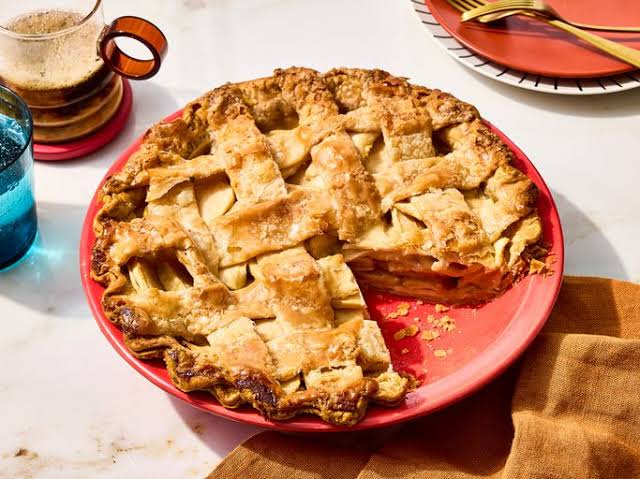

In [ ]:
apple_pie_img = tf.keras.utils.load_img('/content/apple pie test.jpeg')
apple_pie_img

In [ ]:
preprocessed_img = preprocess_image(apple_pie_img)
print(f"Shape of preprocessed_img: {preprocessed_img.shape if preprocessed_img is not None else 'None'}")
print(f"Dtype of preprocessed_img: {preprocessed_img.dtype if preprocessed_img is not None else 'None'}")

Shape of preprocessed_img: (1, 224, 224, 3)
Dtype of preprocessed_img: <dtype: 'float32'>


(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

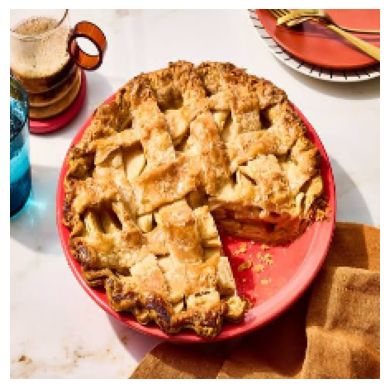

In [ ]:
# we can still plot our preprocessed image as long as we
# divide by 255 (for matplotlib compatiability)
plt.imshow(preprocessed_img[0]/255.) # Access the single image from the batch
plt.axis(False)

In [ ]:
model_pred = loaded_saved_model.predict(preprocessed_img)

NameError: name 'preprocessed_img' is not defined

In [ ]:
# Open the file and extract names into a list
with open('class_names.txt', 'r', encoding='utf-8') as file:
    class_names2 = file.read().splitlines()

print(class_names2)
# Output example: ['cat', 'dog', 'bird']


['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', 'lobster_roll_sandwich', 'macaroni_and_cheese', 'macarons', 'miso_sou

In [ ]:
class_names[model_pred.argmax()]

'apple_pie'

In [ ]:
class_names2[model_pred.argmax()]

'apple_pie'

In [ ]:
model_pred[0]

array([7.03801930e-01, 1.00376969e-03, 1.29916845e-02, 1.65817200e-03,
       1.44911080e-03, 1.22027367e-03, 2.37915483e-05, 8.82370106e-04,
       2.89883651e-03, 1.38816307e-03, 2.74456316e-03, 1.23002799e-02,
       1.32419900e-05, 1.11307781e-04, 8.43735505e-03, 1.57299475e-03,
       2.75489379e-04, 2.64935545e-04, 6.76536642e-04, 3.25496458e-02,
       9.80517478e-04, 4.55161138e-03, 1.17352558e-03, 2.24847870e-04,
       4.20829565e-05, 1.13742007e-03, 5.07617369e-05, 2.41662092e-05,
       1.60981672e-05, 1.34788294e-04, 6.15809813e-06, 6.58288249e-04,
       9.99856391e-04, 9.95958340e-04, 1.56028782e-05, 3.56509787e-04,
       2.49895337e-03, 3.80988000e-04, 1.31389397e-05, 7.06240127e-04,
       2.58798333e-04, 7.20169453e-04, 2.27532280e-03, 9.50350077e-04,
       1.18985772e-02, 3.00843152e-03, 4.03901823e-02, 4.22476660e-05,
       4.78871725e-03, 1.13742007e-03, 6.91125679e-05, 1.85706443e-03,
       1.98457181e-03, 3.25288973e-03, 4.25917329e-03, 1.80697336e-03,
      

In [ ]:
# This cell's functionality has been moved to the prediction cell (cpS8vME4cjP_)
# to ensure true labels are aligned with predictions.
pass

In [ ]:
import tensorflow_datasets as tfds
import tensorflow as tf
import numpy as np

# Ensure class_names is available; re-load ds_info to get it robustly
# This assumes 'food101' dataset is available via tfds.
# If this is run after a kernel restart, ds_info_temp might be `None` if `tfds.load` needs the other split parameter
# for full dataset info.
# For safety and to get class_names, we can load a small part or just the info.
try:
    # Try to load dataset info directly if possible
    ds_info_temp = tfds.builder('food101').info
except Exception:
    # Fallback if builder needs to be created first or if info is not directly accessible
    _, ds_info_temp = tfds.load(name='food101', split=['train'], as_supervised=True, with_info=True)

class_names = ds_info_temp.features['label'].names

# Function for preprocessing images (must be consistent with prior preprocessing)
def preprocess_img_for_metrics(image, label, img_shape=224):
    image = tf.image.resize(image, [img_shape, img_shape])
    return tf.cast(image, tf.float32), label

# Re-load the raw test split of the Food101 dataset to ensure a fresh iterator
# Use the 'validation' split as it was used as 'test_data' throughout the notebook
raw_test_data_for_metrics = tfds.load(name='food101',
                                      split='validation', # Corresponds to 'test_data' used earlier
                                      shuffle_files=False, # Essential for consistent order
                                      as_supervised=True,
                                      with_info=False)

# Apply preprocessing and batching to this fresh dataset for metrics calculation
# Use the same batch size as before (32)
test_data_processed_for_metrics = raw_test_data_for_metrics.map(
    lambda image, label: preprocess_img_for_metrics(image, label, img_shape=224),
    num_parallel_calls=tf.data.AUTOTUNE
).batch(32).prefetch(tf.data.AUTOTUNE)

# Collect true labels and predictions in a single pass
y_true_list = []
y_pred_probs_list = []

print("Collecting true labels and model predictions...")
for images_batch, labels_batch in test_data_processed_for_metrics:
    y_true_list.append(labels_batch)
    y_pred_probs_list.append(loaded_saved_model.predict(images_batch, verbose=0)) # Use verbose=0 to suppress per-batch output

# Concatenate all batches into single NumPy arrays
global true_labels
true_labels = tf.concat(y_true_list, axis=0).numpy()

global test_pred_probs
test_pred_probs = tf.concat(y_pred_probs_list, axis=0).numpy()

# Get predicted class labels (most probable class)
global test_pred
test_pred = tf.argmax(test_pred_probs, axis=1).numpy()

print(f"Shape of true_labels: {true_labels.shape}")
print(f"Shape of test_pred: {test_pred.shape}")
print(f"First 10 true labels: {true_labels[:10]}")
print(f"First 10 predicted labels: {test_pred[:10]}")

# Ensure `test_pred_np` from the next cell (tPj9uqnQfrp-) will use the correct `test_pred` value
test_pred_np = test_pred

Shape of true_labels: (25250,)
Shape of test_pred: (25250,)
First 10 true labels: [ 29  81  91  53  97  97  10  31   3 100]
First 10 predicted labels: [ 29  81  91  53  97  97  10  31   3 100]


In [ ]:
true_labels = test_labels
true_labels

[<tf.Tensor: shape=(32,), dtype=int64, numpy=
 array([93, 83, 98, 40, 60, 13, 36, 92, 21, 25, 29, 81, 66, 81,  1, 92, 67,
        65, 70, 34, 69, 23, 78, 13, 41, 27, 41, 32, 25,  5, 20, 53])>,
 <tf.Tensor: shape=(32,), dtype=int64, numpy=
 array([59, 84, 60, 29, 80, 32, 78, 17,  1, 40, 40, 99,  1, 71, 42,  6, 44,
        44, 27, 79, 16, 51, 12, 17, 99, 13, 42, 24, 54, 36, 80, 26])>,
 <tf.Tensor: shape=(32,), dtype=int64, numpy=
 array([ 68,  57,  48,  79,  44,  81,  43,  27,  47,  46,  22,  99,  70,
        100,  90,  21,  59,   1,  75,  61,  74,  54,  76,  34,  90,  15,
          4,  15,  19,  49, 100,  93])>,
 <tf.Tensor: shape=(32,), dtype=int64, numpy=
 array([62, 28, 12,  4, 66, 55, 32, 19, 42, 63, 91, 16, 97, 79, 41, 95,  4,
        37, 99, 40, 60,  1, 69, 52, 62, 77, 67, 12, 96, 53, 70, 44])>,
 <tf.Tensor: shape=(32,), dtype=int64, numpy=
 array([71, 83, 80, 45, 28, 23, 30, 72, 45, 94, 92, 46, 18, 99, 75, 16, 40,
        83, 16, 60, 32, 36, 94, 48,  0, 65, 29, 56, 37, 87, 65, 64

In [ ]:
# This cell's functionality has been moved to the prediction cell (cpS8vME4cjP_)
# to ensure true labels are aligned with predictions.
pass

In [ ]:
test_pred = tf.argmax(test_pred_probs, axis=1)
test_pred[:10]

<tf.Tensor: shape=(10,), dtype=int64, numpy=array([90, 33,  9, 12, 78, 77, 96,  6, 48,  9])>

In [ ]:
test_pred.dtype == true_labels.dtype

True

In [ ]:
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

# Ensure test_pred is a NumPy array
test_pred_np = np.array(test_pred)

# Calculate accuracy
accuracy = accuracy_score(true_labels, test_pred_np)

# Generate classification report for precision, recall, and f1-score
report = classification_report(true_labels, test_pred_np, output_dict=True)

# Extract overall precision, recall, and f1-score
# Note: 'weighted avg' is often used for multi-class classification to account for class imbalance
precision = report['weighted avg']['precision']
recall = report['weighted avg']['recall']
f1 = report['weighted avg']['f1-score']

results = {
    'accuracy': accuracy,
    'precision': precision,
    'recall': recall,
    'f1': f1
}

print("Calculated Metrics:")
for metric, value in results.items():
    print(f"{metric.capitalize()}: {value:.4f}")

print("\nFull Classification Report:")
print(classification_report(true_labels, test_pred_np))

Calculated Metrics:
Accuracy: 0.8268
Precision: 0.8259
Recall: 0.8268
F1: 0.8259

Full Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.62      0.66       250
           1       0.81      0.85      0.83       250
           2       0.85      0.90      0.87       250
           3       0.82      0.86      0.84       250
           4       0.80      0.78      0.79       250
           5       0.74      0.70      0.72       250
           6       0.84      0.89      0.87       250
           7       0.89      0.94      0.91       250
           8       0.70      0.64      0.67       250
           9       0.82      0.75      0.78       250
          10       0.78      0.76      0.77       250
          11       0.82      0.89      0.85       250
          12       0.92      0.88      0.90       250
          13       0.79      0.85      0.82       250
          14       0.82      0.81      0.81       250
          15       0.75  

In [ ]:
loaded_saved_model.evaluate(test_data)

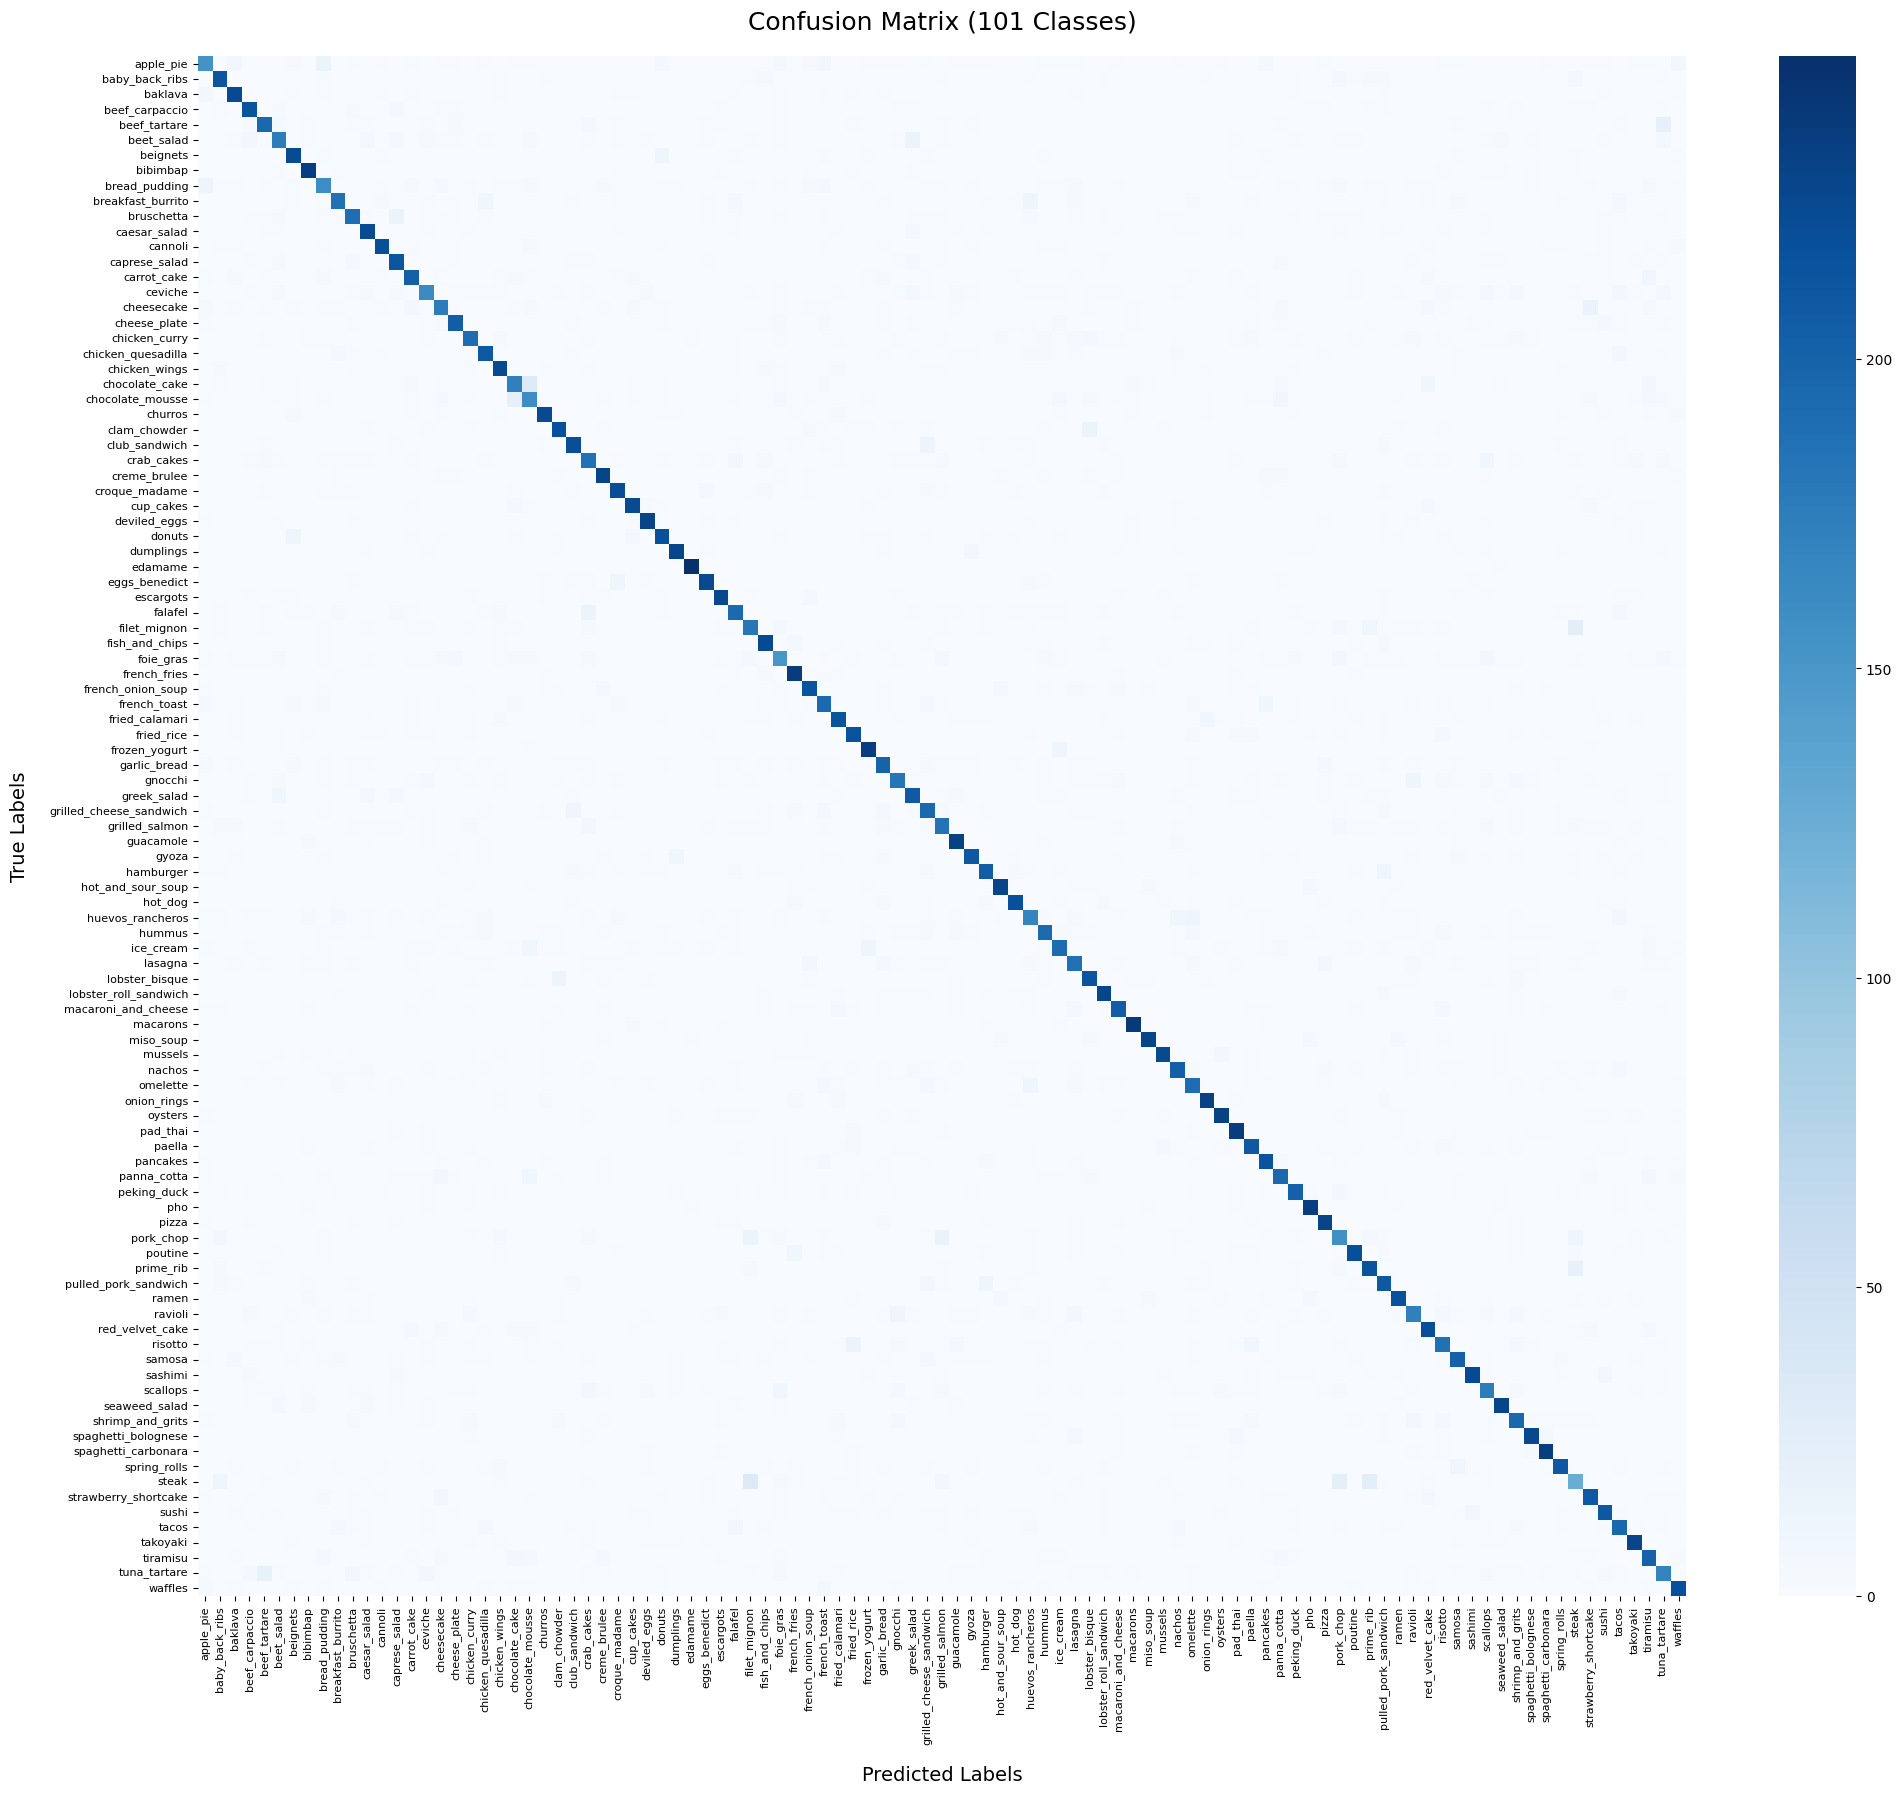

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix using your existing variables
cm = confusion_matrix(true_labels, test_pred_np)

# Significantly increase the figure size for 101 classes
plt.figure(figsize=(24, 20))

# Create the heatmap
# annot=False is used because 10,000+ numbers will overlap.
# If you must see numbers, use: annot=True, annot_kws={"size": 4}
sns.heatmap(cm, annot=False, cmap='Blues', cbar=True,
            xticklabels=class_names, yticklabels=class_names)

# Add title and axis labels
plt.title('Confusion Matrix (101 Classes)', pad=20, fontsize=18)
plt.xlabel('Predicted Labels', fontsize=14, labelpad=15)
plt.ylabel('True Labels', fontsize=14, labelpad=15)

# Rotate x-axis labels by 90 degrees to prevent overlapping text
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

# Save the matrix as a high-res image file (must be called before plt.show())
plt.savefig('confusion_matrix_101_classes.png', dpi=300, bbox_inches='tight')

# Display the plot inline in the Jupyter Notebook
plt.show()

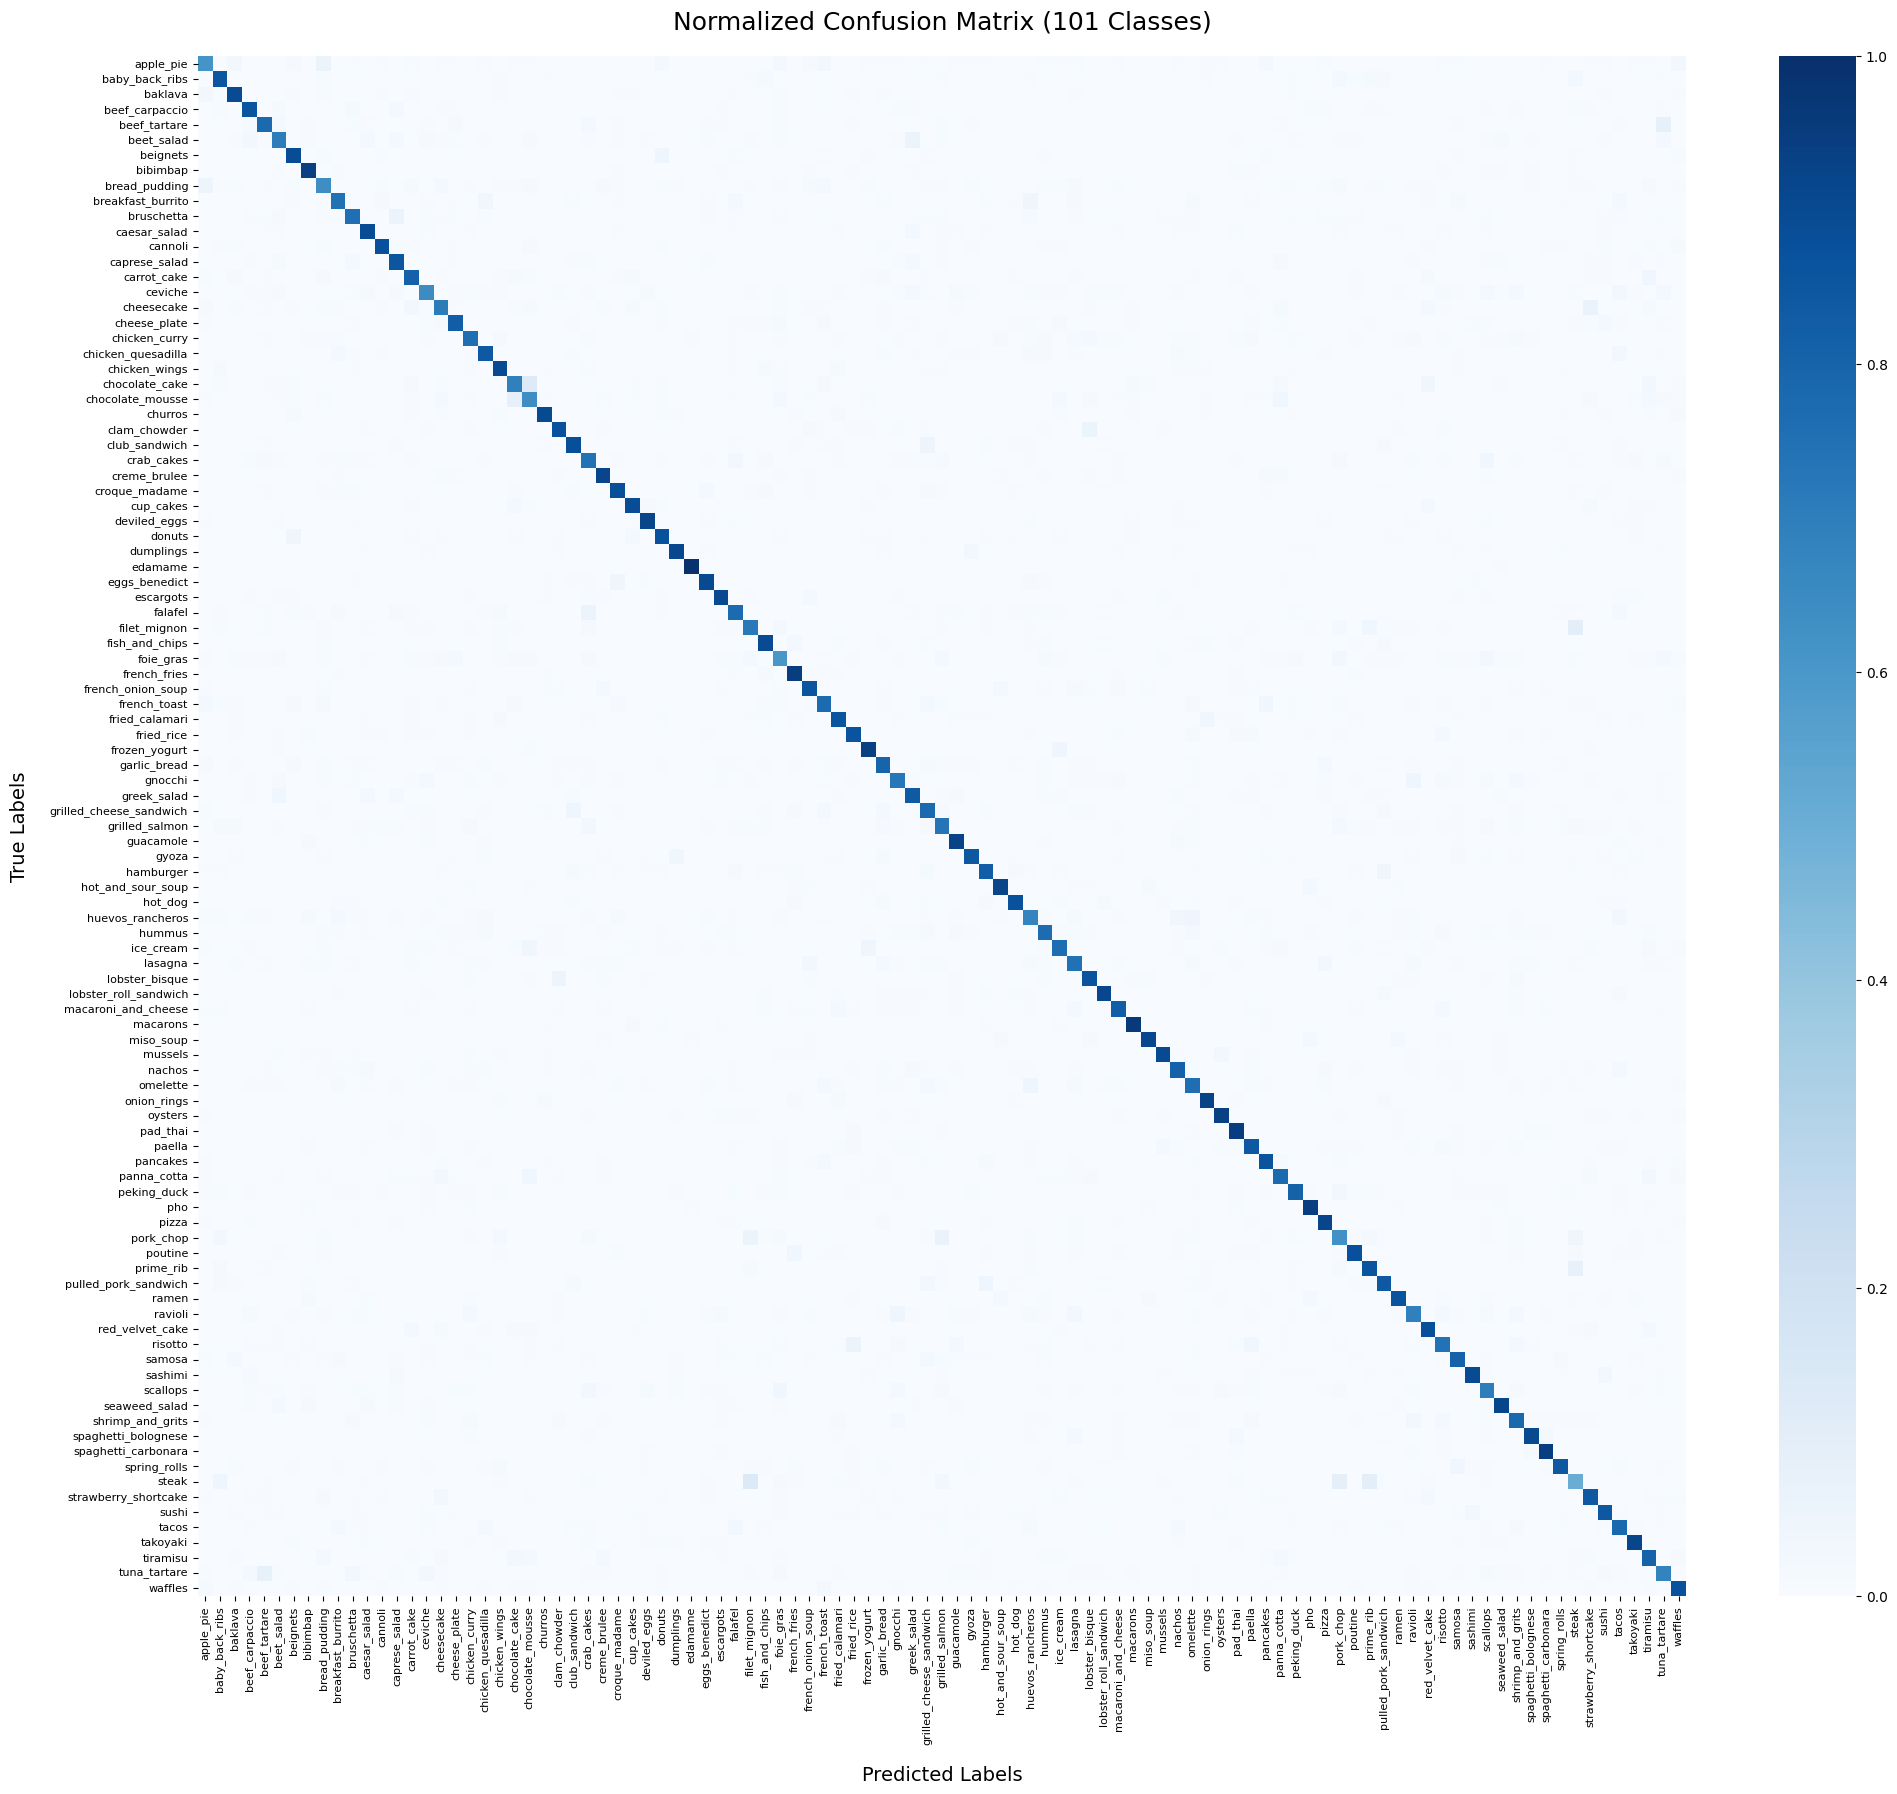

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate the normalized confusion matrix
# normalize='true' normalizes across the true labels (rows)
cm_normalized = confusion_matrix(true_labels, test_pred_np, normalize='true')

# Set up the figure size for 101 classes
plt.figure(figsize=(24, 20))

# Create the heatmap
# vmin=0 and vmax=1 keep the color scale locked between 0 and 1 (0% to 100%)
sns.heatmap(cm_normalized, annot=False, cmap='Blues', cbar=True,
            xticklabels=class_names, yticklabels=class_names,
            vmin=0, vmax=1)

# Add title and axis labels
plt.title('Normalized Confusion Matrix (101 Classes)', pad=20, fontsize=18)
plt.xlabel('Predicted Labels', fontsize=14, labelpad=15)
plt.ylabel('True Labels', fontsize=14, labelpad=15)

# Rotate axis labels to prevent overlap
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

# Save and display the image
plt.savefig('normalized_confusion_matrix_101.png', dpi=300, bbox_inches='tight')
plt.show()